In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
df = pd.read_csv("../archive/amz_uk_price_prediction_dataset.csv")

In [3]:
df = df[df.columns[df.isnull().mean() < 0.8]]

In [5]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 495.8 MB


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: *Understand the relationship between product categories and their best-seller status.*

**1. Crosstab Analysis:**

    - Create a crosstab between the product `category` and the `isBestSeller` status.

In [20]:
ct_result = pd.crosstab(df["category"], df["isBestSeller"]).sort_values(by=True, ascending=False)
crosstab_result
ct_result

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
...,...,...
Blank Media Cases & Wallets,243,0
Boating Footwear,140,0
Boxes & Organisers,911,0


    - Are there categories where being a best-seller is more prevalent? 

*"Grocery" and "Health & Personal Care" has significantly more best seller products*

**2.Statistical Tests:**

    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.

In [13]:
from scipy.stats import chi2_contingency

In [27]:
chi2, p, dof, expected = chi2_contingency(ct_result)
print(f"Chi-square = {chi2:.2f}, dof = {dof}, p-value = {p:.4f}")

Chi-square = 36540.20, dof = 295, p-value = 0.0000


    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [23]:
n = ct_result.to_numpy().sum()
min_dim = min(ct_result.shape) - 1   # now 1
cramers_v = np.sqrt(chi2 / (n * min_dim))
print(f"Cramér's V = {cramers_v:.3f}")

Cramér's V = 0.122


**3. Visualizations:**

    - Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

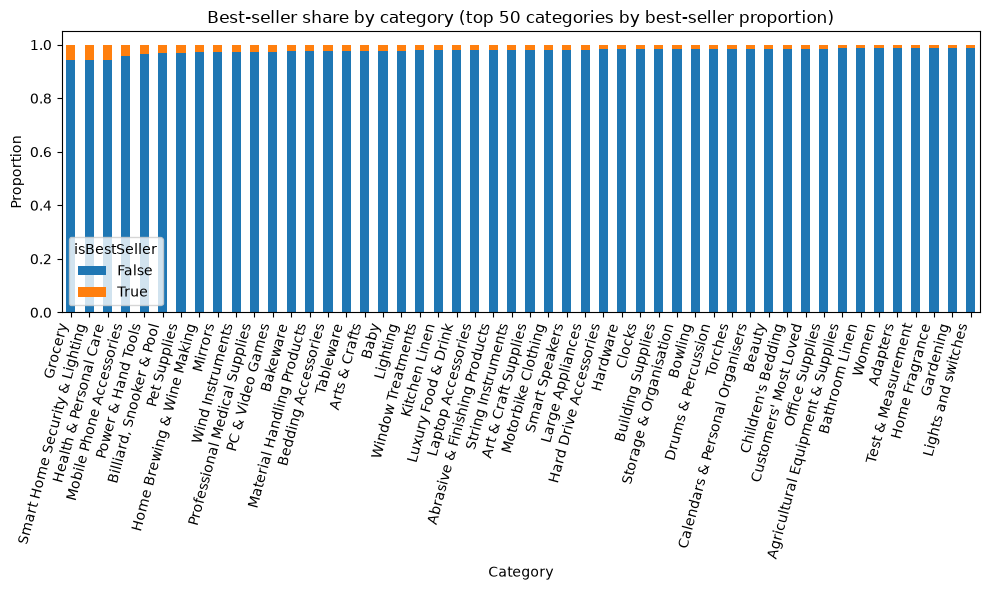

In [79]:
prop_all = ct_result.div(ct_result.sum(axis=1), axis=0)

top10_prop = prop_all[True].sort_values(ascending=False).head(50).index

ct_top_prop = prop_all.loc[top10_prop]

ct_top_prop.plot(kind="bar", stacked=True, figsize=(10, 6))
plt.title("Best-seller share by category (top 50 categories by best-seller proportion)")
plt.ylabel("Proportion")
plt.xlabel("Category")
plt.xticks(rotation=75, ha="right")
plt.legend(title="isBestSeller")
plt.tight_layout()
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective:** *Investigate how different product categories influence product prices.*

**0. Preliminary Step: Remove outliers in product prices.**

In [38]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

df_clean = df[(df["price"] >= lower) & (df["price"] <= upper)].copy()
print(f"Bounds: {lower:.2f} to {upper:.2f}")
print(f"Rows before: {len(df)}, after: {len(df_clean)}")

Bounds: -44.01 to 99.99
Rows before: 2443651, after: 2115963


**1. Violin Plots:**

    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.

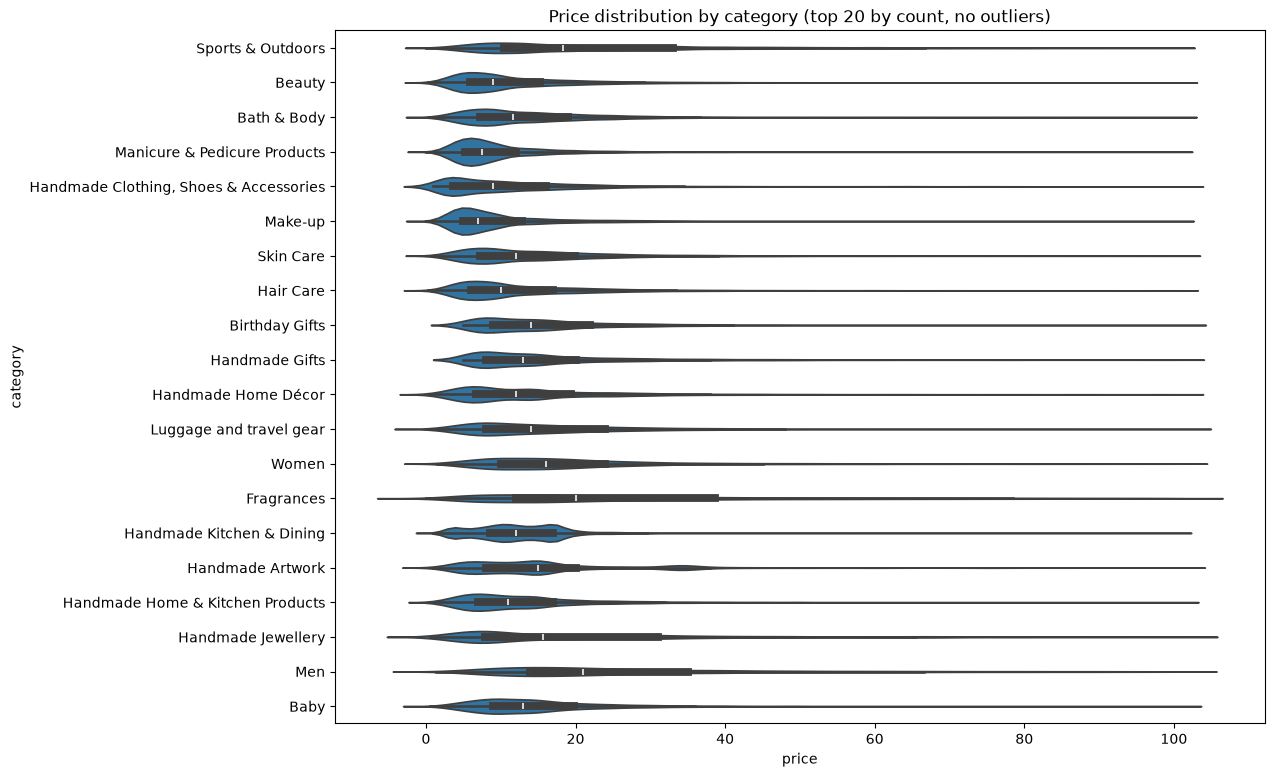

In [42]:
top20_cats = df_clean["category"].value_counts().head(20).index
plt.figure(figsize=(12, 9))
sns.violinplot(data=df_clean[df_clean["category"].isin(top20_cats)],
               x="price", y="category", order=top20_cats)
plt.title("Price distribution by category (top 20 by count, no outliers)")
plt.show()

    - Which product category tends to have the highest median price? Don't filter here by top categories.

In [44]:
df_clean.groupby("category")["price"].median().sort_values(ascending=False)

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

**2. Bar Charts:**

    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

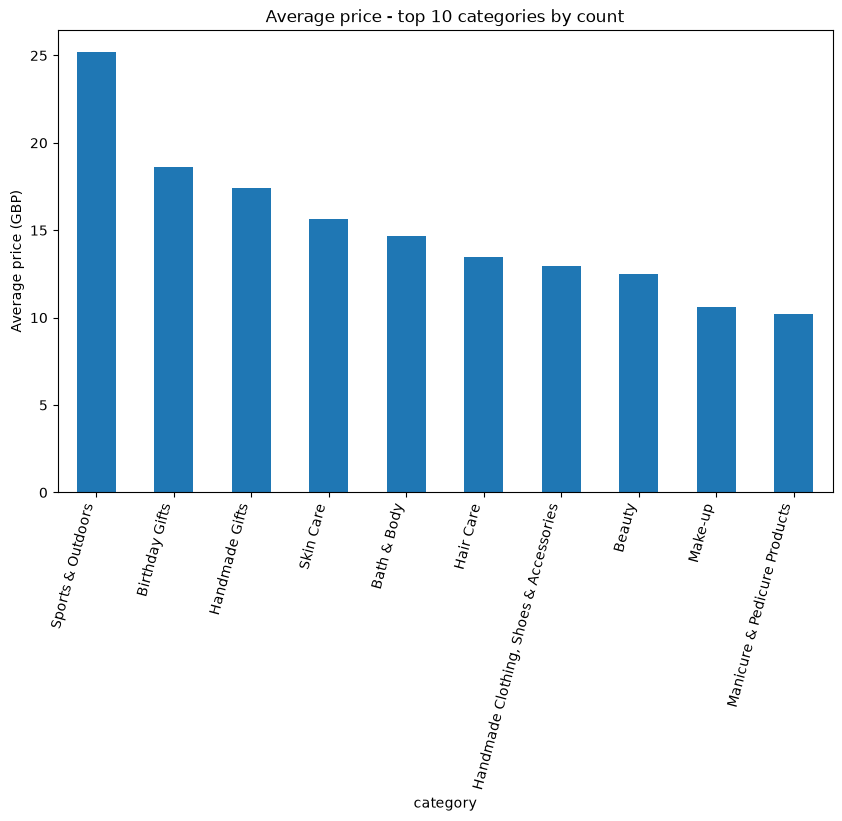

In [47]:
top10_cats_clean = df_clean["category"].value_counts().head(10).index
avg_price_top10 = (df_clean[df_clean["category"].isin(top10_cats_clean)]
                   .groupby("category")["price"].mean()
                   .sort_values(ascending=False))

avg_price_top10.plot(kind="bar", figsize=(10, 6))
plt.title("Average price - top 10 categories by count")
plt.ylabel("Average price (GBP)")
plt.xticks(rotation=75, ha="right")
plt.show()

    - Which product category commands the highest average price? Don't filter here by top categories.

In [48]:
df_clean.groupby("category")["price"].mean().sort_values(ascending=False).head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

**3. Box Plots:**

    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.

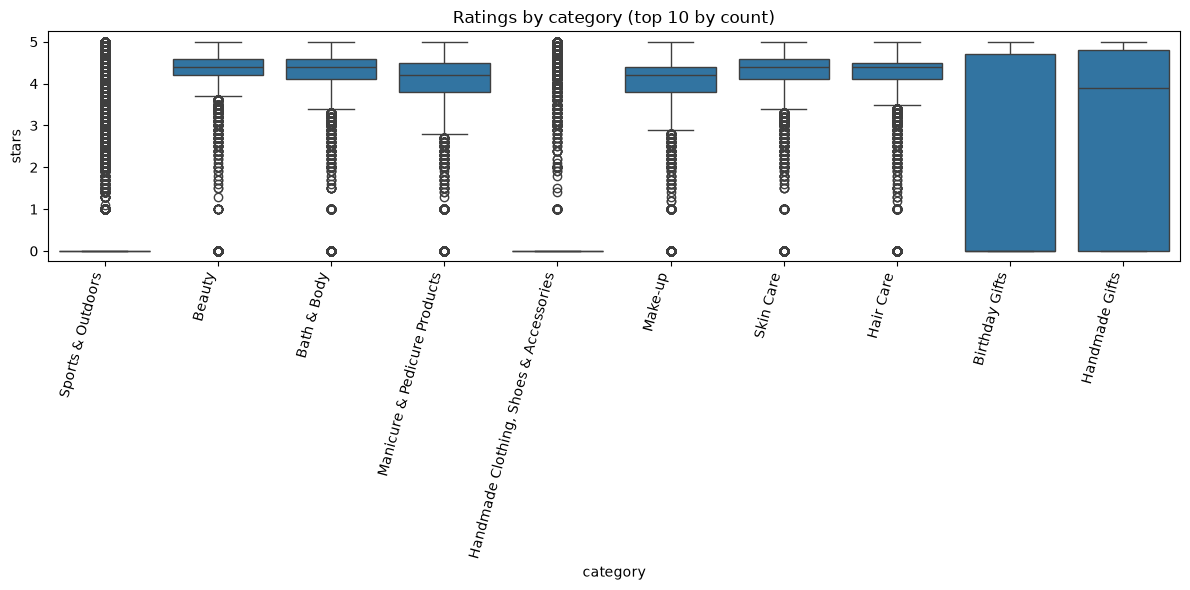

In [49]:
top10_cats_clean = df_clean["category"].value_counts().head(10).index
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_clean[df_clean["category"].isin(top10_cats_clean)],
            x="category", y="stars", order=top10_cats_clean)
plt.title("Ratings by category (top 10 by count)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [51]:
df_clean.groupby("category")["stars"].median().sort_values(ascending=False)

category
Computer Memory                                 4.7
Beer, Wine & Spirits                            4.6
Building & Construction Toys                    4.6
Office Paper Products                           4.6
Kids' Play Figures                              4.6
                                               ... 
Synthesisers, Samplers & Digital Instruments    0.0
Tablets                                         0.0
Action Cameras                                  0.0
3D Printing & Scanning                          0.0
eBook Readers & Accessories                     0.0
Name: stars, Length: 296, dtype: float64

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective:** *Analyze how product ratings (`stars`) correlate with product prices.*

**1. Correlation Coefficients:**

    - Calculate the correlation coefficient between `price` and `stars`.

In [54]:
from scipy import stats

In [55]:
corr = df_clean["price"].corr(df_clean["stars"])
r, p_val = stats.pearsonr(df_clean["price"], df_clean["stars"])
print(f"Pearson r = {corr:.3f}, p-value = {p_val:.4g}")

Pearson r = -0.078, p-value = 0


    - Is there a significant correlation between product price and its rating?

*There is a statistically significant but very weak correlation between price and rating.*

**2. Visualizations:**

    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

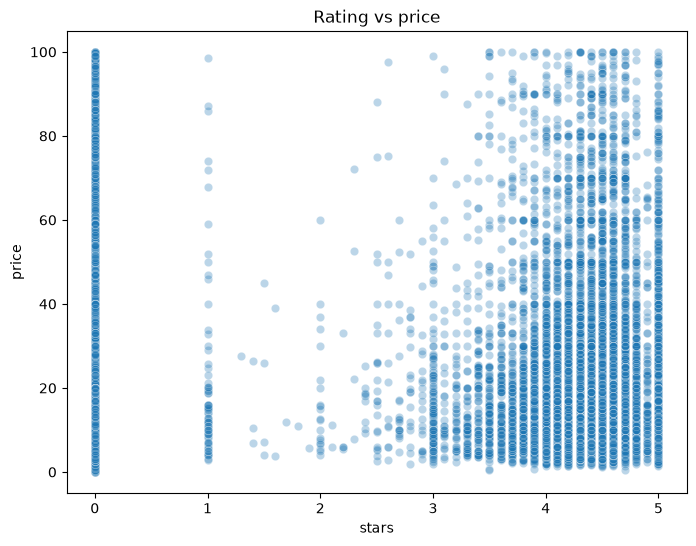

In [58]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_clean.sample(min(20000, len(df_clean)), random_state=42),
                x="stars", y="price", alpha=0.3)
plt.title("Rating vs price")
plt.show()

    - Use a correlation heatmap to visualize correlations between all numerical variables.

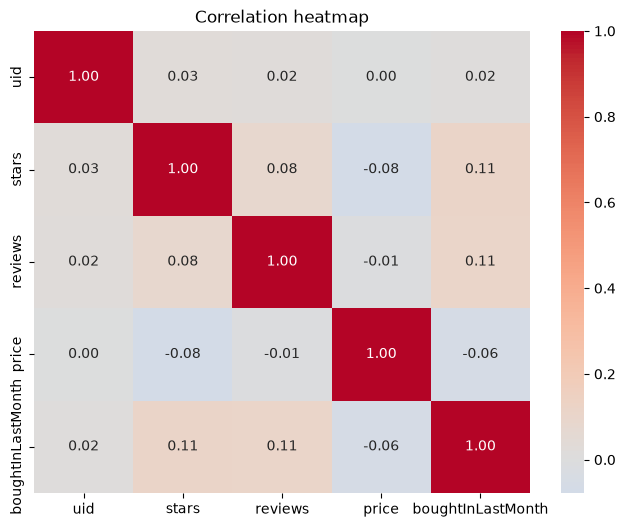

In [61]:
numeric_df = df_clean.select_dtypes(include="number")
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

    - Examine if product prices typically follow a normal distribution using a QQ plot. 

In [63]:
import statsmodels.api as sm

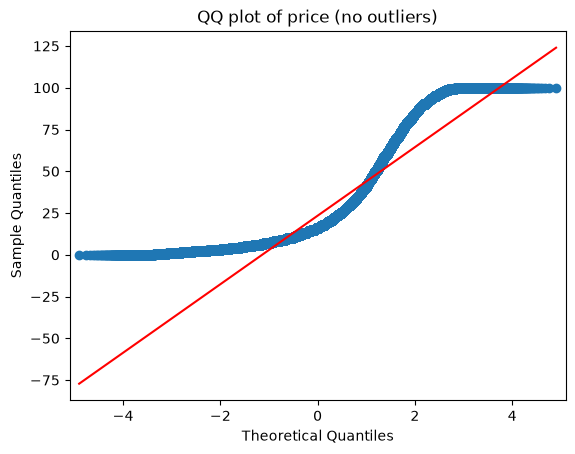

In [64]:
sm.qqplot(df_clean["price"], line="s")
plt.title("QQ plot of price (no outliers)")
plt.show()

### Business Centric Report

**Scope: We analysed 2.44M Amazon UK products across 296 categories. For the price analysis we removed outliers with the IQR method, which excluded about 13% of products (everything above £99.99). The unfiltered results are in the bonus section.**

**1. Best-seller status depends on category, but only moderately.**
The Chi-square test (χ² = 36,540, p < 0.001) shows that best-seller status is not independent of category.
Cramér’s V is 0.12, a weak-to-moderate association. Category matters, but it explains only part of what makes a product a best-seller.
Grocery and Health & Personal Care have the highest share of best-sellers (about 5.8% each), while very large categories such as Sports & Outdoors have almost none (330 out of 836K products, about 0.04%).
Implication: best-seller status is much more attainable in smaller, focused categories than in crowded ones, so competition and visibility are likely to matter as much as the product itself.

**2. Prices are driven by the type of product.**
Without outliers, the highest-priced categories are computing hardware and sports gear: Desktop PCs (£74 median), Tablets, Graphics Cards and Motherboards (£68.77 mean). The cheapest are Office Paper Products (£4.37 median) and Arts & Crafts (£5.99).
Keeping outliers changes the picture: high-ticket electronics dominate, with Laptops (£1,043 median) and 3D Printers (£1,018 mean) at the top. These premium items drive most of the revenue per unit.
Prices are right-skewed (many cheap items and a long tail of expensive ones), so medians describe a typical product better than averages.

**3. Price does not buy better ratings.**
The correlation between price and rating is r = -0.078 (-0.125 with outliers). It is statistically significant, but practically negligible, since price explains less than 1% of rating variation.
Computer Memory has the highest median rating (4.7), followed by several categories at 4.6.
Many products have no ratings at all (0 stars), and some categories, such as Tablets and Action Cameras, have a median of 0, so rating comparisons across categories should be read with care.

**Recommendations:**
Don’t assume a higher price implies better customer satisfaction. Invest in product quality and reviews rather than price positioning.
For new sellers, categories with a higher best-seller share offer a better chance of visibility.
Report medians alongside averages, and analyse premium segments such as laptops separately, since they distort the overall price picture.

**Limitations:** *Correlation does not imply causation, and unrated products (0 stars) may bias the rating results.*

**Bonus:**

**-----------------------------------------------------------------------------------------------------------------**

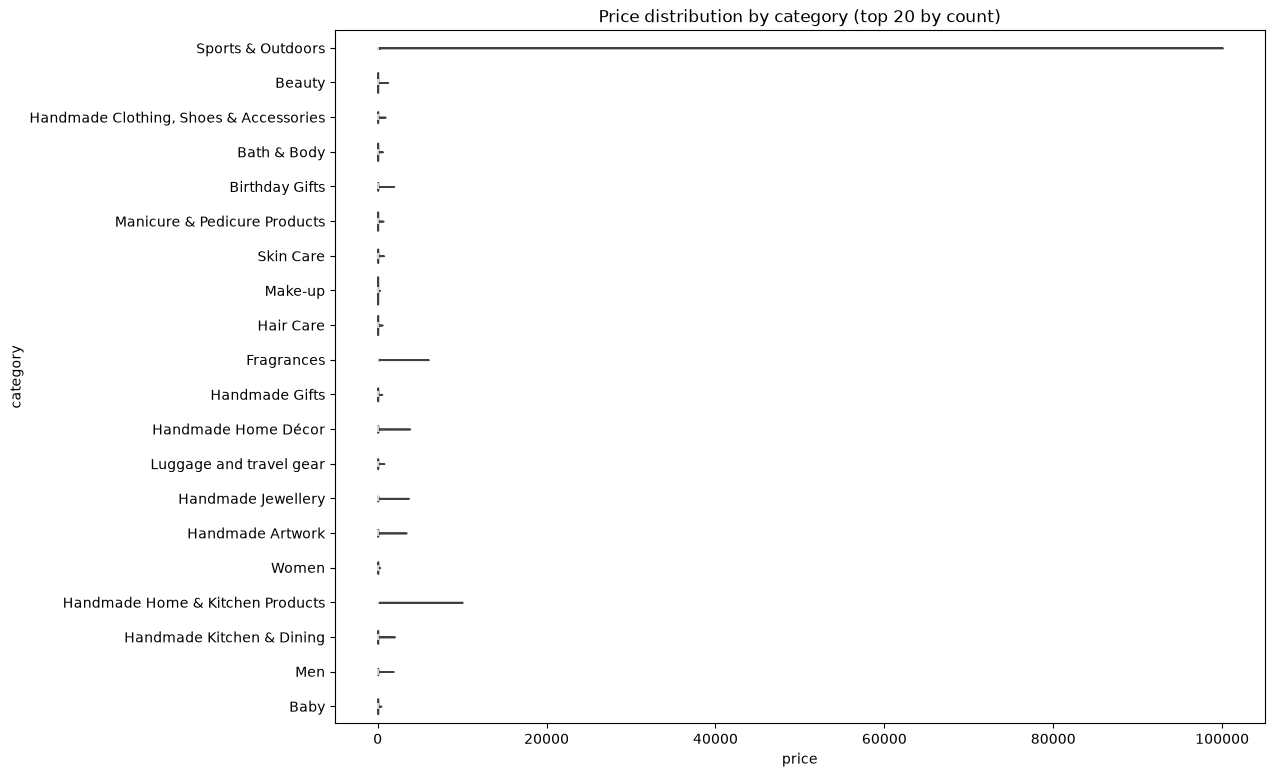

In [80]:
top20_cats = df["category"].value_counts().head(20).index
plt.figure(figsize=(12, 9))
sns.violinplot(data=df[df["category"].isin(top20_cats)],
               x="price", y="category", order=top20_cats)
plt.title("Price distribution by category (top 20 by count)")
plt.show()

    - Which product category tends to have the highest median price? Don't filter here by top categories.

In [68]:
df.groupby("category")["price"].median().sort_values(ascending=False)

category
Laptops                      1042.725
Desktop PCs                   810.400
Snowboards                    366.725
Home Audio Record Players     326.080
3D Printers                   319.000
                               ...   
Adapters                        7.050
Make-up                         7.000
Signs & Plaques                 6.990
Arts & Crafts                   5.990
Office Paper Products           4.380
Name: price, Length: 296, dtype: float64

**2. Bar Charts:**

    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

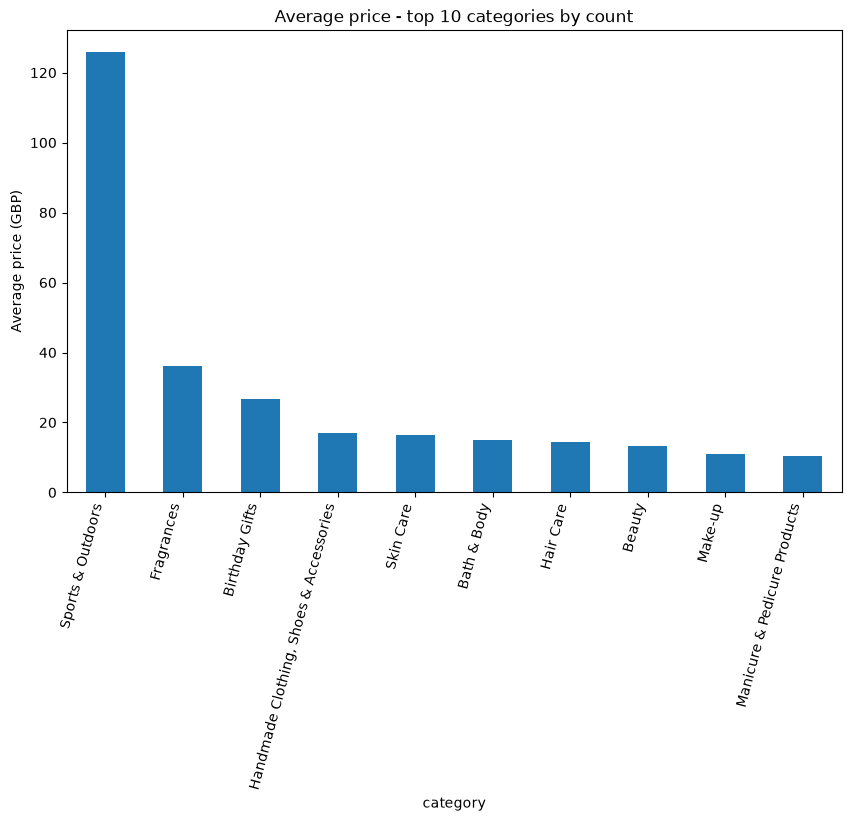

In [77]:
top10_cats = df["category"].value_counts().head(10).index
avg_price_top10 = (df[df["category"].isin(top10_cats)]
                   .groupby("category")["price"].mean()
                   .sort_values(ascending=False))

avg_price_top10.plot(kind="bar", figsize=(10, 6))
plt.title("Average price - top 10 categories by count")
plt.ylabel("Average price (GBP)")
plt.xticks(rotation=75, ha="right")
plt.show()

    - Which product category commands the highest average price? Don't filter here by top categories.

In [70]:
df.groupby("category")["price"].mean().sort_values(ascending=False).head(10)

category
Laptops                       1087.987827
3D Printers                   1018.036129
Desktop PCs                    926.816064
Home Office Furniture          622.135898
Test & Measurement             559.382973
Home Audio Record Players      529.665585
CPUs                           514.519317
Digital Cameras                496.156185
Material Handling Products     487.191813
Graphics Cards                 444.746827
Name: price, dtype: float64

**3. Box Plots:**

    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.

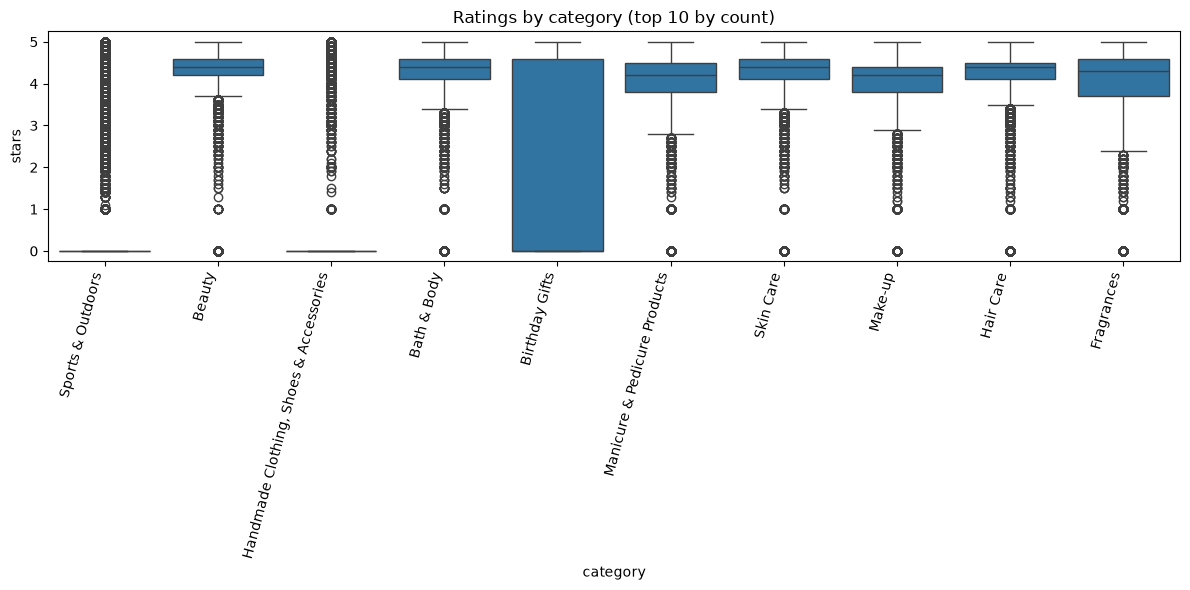

In [78]:
top10_cats = df["category"].value_counts().head(10).index
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[df["category"].isin(top10_cats)],
            x="category", y="stars", order=top10_cats)
plt.title("Ratings by category (top 10 by count)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [72]:
df.groupby("category")["stars"].median().sort_values(ascending=False)

category
Computer Memory                                 4.7
CPUs                                            4.6
Building & Construction Toys                    4.6
Laptop Accessories                              4.6
Hobbies                                         4.6
                                               ... 
Synthesisers, Samplers & Digital Instruments    0.0
Tablets                                         0.0
Action Cameras                                  0.0
3D Printing & Scanning                          0.0
eBook Readers & Accessories                     0.0
Name: stars, Length: 296, dtype: float64

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective:** *Analyze how product ratings (`stars`) correlate with product prices.*

**1. Correlation Coefficients:**

    - Calculate the correlation coefficient between `price` and `stars`.

In [54]:
from scipy import stats

In [73]:
corr = df["price"].corr(df["stars"])
r, p_val = stats.pearsonr(df["price"], df["stars"])
print(f"Pearson r = {corr:.3f}, p-value = {p_val:.4g}")

Pearson r = -0.125, p-value = 0


    - Is there a significant correlation between product price and its rating?

*There is a statistically significant but very weak correlation between price and rating.*

**2. Visualizations:**

    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

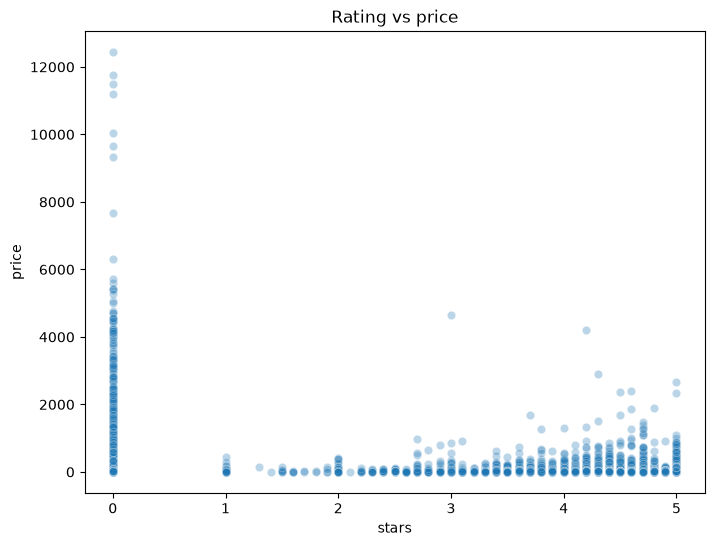

In [74]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df.sample(min(20000, len(df)), random_state=42),
                x="stars", y="price", alpha=0.3)
plt.title("Rating vs price")
plt.show()

    - Use a correlation heatmap to visualize correlations between all numerical variables.

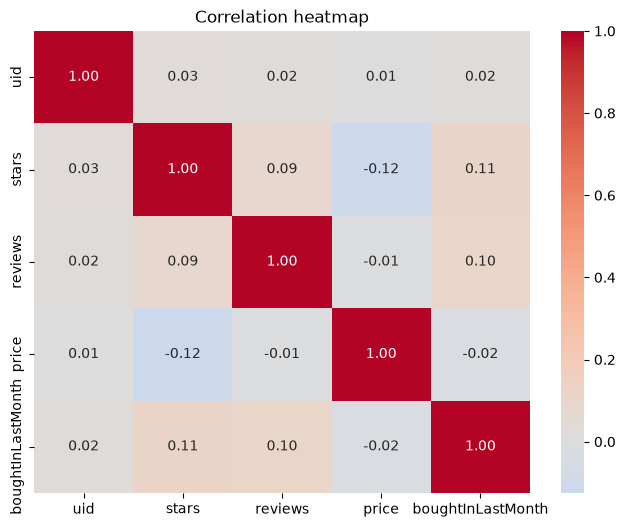

In [75]:
numeric_df = df.select_dtypes(include="number")
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

    - Examine if product prices typically follow a normal distribution using a QQ plot. 

In [63]:
import statsmodels.api as sm

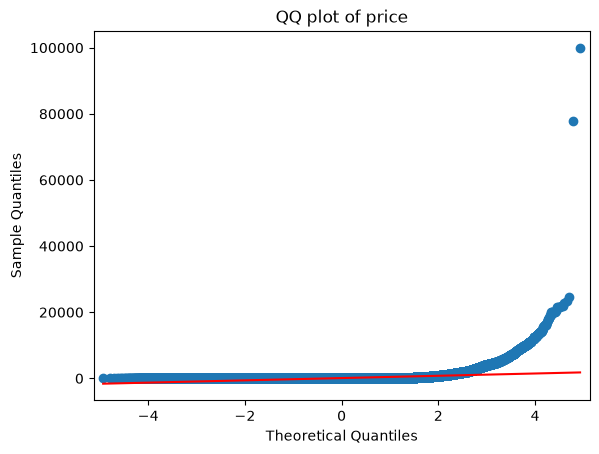

In [81]:
sm.qqplot(df["price"], line="s")
plt.title("QQ plot of price")
plt.show()